## 1. Model Setup and Contract Selection

This section defines the underlying stock price, strike price, risk-free interest rate, valuation date, and option expiration date for the finite-difference pricing models.

We select the PLTR call option expiring on January 15, 2027, with a strike price of $210. This contract is close to at-the-money and has 98 calendar days to maturity, making it the eligible expiration closest to 90 days.

The time to maturity is calculated using an Actual/365 convention. The same contract and its market-implied volatility will be used consistently across the numerical pricing methods in Question 2.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from time import perf_counter

s0 = 209.05
K = 210
r = 0.045

valuation_date = pd.Timestamp("2026-10-09")
expiration_date = pd.Timestamp("2027-01-15")

T = (expiration_date-valuation_date).days/365
print("Time to maturity: ", T)

Time to maturity:  0.2684931506849315


## 2. Explicit Finite-Difference Method

This section implements the explicit finite-difference scheme for the transformed Black–Scholes heat equation.

The value at each new time step is calculated from three adjacent grid points at the previous time step. 

## 3. Heat Equation Transformation and Initial Condition

We transform the Black–Scholes PDE into the standard heat equation using log-moneyness and transformed time.

The European call payoff is converted into the initial condition of the heat equation. This initial profile provides the starting values for the finite-difference grid.

In [12]:
sigma = 0.497988  # Selected call implied volatility

k = 2*r/(sigma**2)
a = (1-k)/2
b = -((k+1)**2)/4

x_min = -1.0
x_max = 1.0
M = 100

x = np.linspace(x_min, x_max, M+1)

u_initial = np.exp(-a * x) * np.maximum(np.exp(x) - 1, 0)

print("x shape:", x.shape)
print("Initial condition shape:", u_initial.shape)


x shape: (101,)
Initial condition shape: (101,)


## 4. Explicit FDM: Spatial and Time Grid

This section constructs the two-dimensional finite-difference grid for the transformed Black–Scholes heat equation.

We select the number of time steps to satisfy the explicit scheme's stability condition, alpha <= 0.5. The grid stores the transformed option values at each spatial node and time step.

In [13]:
dx = (x_max-x_min)/M
tau_max = 0.5*sigma**2*T

alpha_target = 0.4
N = int(np.ceil(tau_max/(alpha_target*dx**2)))

dtau = tau_max/ N
alpha = dtau/dx**2

u = np.zeros((N+1, M+1))
u[0:,] = u_initial

print("dx:", dx)
print("tau_max:", tau_max)
print("Time steps N:", N)
print("dtau:", dtau)
print("Actual alpha:", alpha)
print("Grid shape:", u.shape)


dx: 0.02
tau_max: 0.03329208317549589
Time steps N: 209
dtau: 0.00015929226399758798
Actual alpha: 0.39823065999396995
Grid shape: (210, 101)


## 5. Boundary Conditions for the Explicit FDM Grid

The finite-difference method requires boundary values at both ends of the truncated log-moneyness domain.

For a European call, the lower boundary approaches zero as the stock price approaches zero. At the upper boundary, the call value approaches the stock price minus the discounted strike.

These conditions are transformed into the heat-equation variables and applied at every time step.

In [14]:
tau = np.linspace(0, tau_max, N+1)

u[:,0] = 0.0
u[:, -1] = (
    np.exp(-a * x_max - b * tau)
    * (np.exp(x_max) - np.exp(-k * tau))
)

## 6. Explicit FDM Time-Stepping

This section solves the transformed Black–Scholes heat equation using the explicit finite-difference scheme.

At each time step, the transformed option value at an interior grid point is calculated from three adjacent values at the previous time step. The boundary values remain fixed according to the specified boundary conditions.

In [15]:
start_time = perf_counter()

for n in range(N):
    u[n + 1, 1:-1] = (
        alpha * u[n, :-2]
        + (1 - 2 * alpha) * u[n, 1:-1]
        + alpha * u[n, 2:]
    )

runtime = perf_counter() - start_time

print("Runtime:", runtime)
print("Final grid shape:", u.shape)

Runtime: 0.0016967999981716275
Final grid shape: (210, 101)


## 7. Recovering the Call Price from the Heat Equation

The explicit finite-difference scheme produces the transformed solution \(u(x,\tau)\).

To recover the European call price, we apply the inverse Black–Scholes transformation. Since the current log-moneyness may not coincide with a spatial grid point, linear interpolation is used to estimate the transformed value at the current stock price.

In [16]:
x0 = np.log(s0 / K)

u_at_x0 = np.interp(x0, x, u[-1, :])

call_fdm = K * np.exp(a * x0 + b * tau_max) * u_at_x0

print("Current log-moneyness:", x0)
print("Interpolated u:", u_at_x0)
print("Explicit FDM Call Price:", call_fdm)
print("Runtime:", runtime)

Current log-moneyness: -0.004534072914894623
Interpolated u: 0.10744048903413676
Explicit FDM Call Price: 22.18429801436345
Runtime: 0.0016967999981716275


## 8. Validation Against the Black–Scholes Analytical Solution

We validate the explicit finite-difference solution against the Black–Scholes analytical call price using identical model inputs.

The absolute pricing error is calculated as the absolute difference between the finite-difference price and the analytical benchmark. This provides a numerical accuracy check before conducting grid refinement and stability experiments.

In [17]:
d1 = (np.log(s0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
d2 = d1 - sigma * np.sqrt(T)

call_bs = s0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

absolute_error = abs(call_fdm - call_bs)

print(f"Black-Scholes Price: {call_bs:.6f}")
print(f"Explicit FDM Price:  {call_fdm:.6f}")
print(f"Absolute Error:      {absolute_error:.6f}")
print(f"FDM Runtime:         {runtime:.6f} seconds")

Black-Scholes Price: 22.175020
Explicit FDM Price:  22.184298
Absolute Error:      0.009278
FDM Runtime:         0.001697 seconds


## 9. Recovering the Option Price Curve

The final time layer of the transformed heat-equation solution contains option values across the spatial grid.

We first convert the log-moneyness grid back into stock prices and apply the inverse transformation to recover the European call price curve. This curve will subsequently be used to estimate Delta and Gamma using finite differences.

In [18]:
S_grid = K * np.exp(x)

C_grid = (
    K * np.exp(a * x + b * tau_max) * u[-1, :]
)

print("Stock price grid shape:", S_grid.shape)
print("Call price grid shape:", C_grid.shape)

Stock price grid shape: (101,)
Call price grid shape: (101,)


## 10. Estimating Delta and Gamma from the FDM Price Curve

Delta and Gamma are estimated by numerically differentiating the finite-difference call price curve with respect to the underlying stock price.

Since the stock-price grid is non-uniform after transforming from log-moneyness, the actual stock-price coordinates are supplied to `np.gradient()`.

The resulting Greeks are interpolated at the current underlying stock price.

In [19]:
delta_grid = np.gradient(C_grid, S_grid, edge_order=2)

gamma_grid = np.gradient(delta_grid, S_grid, edge_order=2)

delta_fdm = np.interp(s0, S_grid, delta_grid)
gamma_fdm = np.interp(s0, S_grid, gamma_grid)

print(f"Explicit FDM Delta: {delta_fdm:.6f}")
print(f"Explicit FDM Gamma: {gamma_fdm:.6f}")

Explicit FDM Delta: 0.562642
Explicit FDM Gamma: 0.007285


## 11. Validation of FDM Greeks

The finite-difference Delta and Gamma are compared with their Black–Scholes analytical counterparts.

Absolute errors are reported separately for Delta and Gamma to evaluate the accuracy of the numerical differentiation.

In [20]:
delta_bs = norm.cdf(d1)

gamma_bs = norm.pdf(d1) / (s0 * sigma * np.sqrt(T))

greeks_comparison = pd.DataFrame({
    "Method": ["Black-Scholes", "Explicit FDM"],
    "Delta": [delta_bs, delta_fdm],
    "Gamma": [gamma_bs, gamma_fdm]
})

print(greeks_comparison)

print("Delta Absolute Error:", abs(delta_fdm - delta_bs))
print("Gamma Absolute Error:", abs(gamma_fdm - gamma_bs))

          Method     Delta     Gamma
0  Black-Scholes  0.562879  0.007304
1   Explicit FDM  0.562642  0.007285
Delta Absolute Error: 0.00023693991979611972
Gamma Absolute Error: 1.8744227031707028e-05


## 12. Reusable Explicit Finite-Difference Solver

The explicit finite-difference implementation is encapsulated in a reusable function to facilitate grid refinement and stability analysis.

The function constructs the transformed spatial and time grids, applies the initial and boundary conditions, performs explicit time stepping, and recovers the European call price at the current underlying price.

The spatial resolution and target stability parameter are configurable to support convergence experiments.

In [21]:
def explicit_fdm(M, x_min=-1.0, x_max=1.0, alpha_target=0.4, N=None, return_grid=False):

    # Transformation parameters
    k = 2 * r / sigma**2
    a = (1 - k) / 2
    b = -(k + 1)**2 / 4

    # Spatial grid
    x = np.linspace(x_min, x_max, M + 1)
    dx = (x_max - x_min) / M

    # Time grid
    tau_max = 0.5 * sigma**2 * T
    if N is None:
        N = int(np.ceil(tau_max / (alpha_target * dx**2)))

    dtau = tau_max / N
    alpha = dtau / dx**2

    # Solution matrix
    u = np.zeros((N + 1, M + 1))

    # Initial condition: European call payoff
    u[0, :] = np.exp(-a * x) * np.maximum(np.exp(x) - 1, 0)

    # Boundary conditions
    tau = np.linspace(0, tau_max, N + 1)

    u[:, 0] = 0.0

    u[:, -1] = (
        np.exp(-a * x_max - b * tau)
        * (np.exp(x_max) - np.exp(-k * tau))
    )

    # Explicit time stepping
    start_time = perf_counter()

    for n in range(N):
        u[n + 1, 1:-1] = (
            alpha * u[n, :-2]
            + (1 - 2 * alpha) * u[n, 1:-1]
            + alpha * u[n, 2:]
        )

    runtime = perf_counter() - start_time

    # Recover the call price curve
    S_grid = K * np.exp(x)
    C_grid = K * np.exp(a * x + b * tau_max) * u[-1, :]

    # Estimate Greeks
    delta_grid = np.gradient(C_grid, S_grid, edge_order=2)
    gamma_grid = np.gradient(delta_grid, S_grid, edge_order=2)

    # Interpolate at the current stock price
    call_price = np.interp(s0, S_grid, C_grid)
    delta = np.interp(s0, S_grid, delta_grid)
    gamma = np.interp(s0, S_grid, gamma_grid)

    result = {
        "M": M,
        "N": N,
        "alpha": alpha,
        "Price": call_price,
        "Delta": delta,
        "Gamma": gamma,
        "Runtime": runtime
    }

    if return_grid:
        result["S_grid"] = S_grid
        result["C_grid"] = C_grid

    return result

In [22]:
result = explicit_fdm(M=100, alpha_target=0.4)

print(pd.Series(result))

M          100.000000
N          209.000000
alpha        0.398231
Price       22.182749
Delta        0.562642
Gamma        0.007285
Runtime      0.001142
dtype: float64


In [23]:
result = explicit_fdm(M=100, alpha_target=0.4)

print("Type:", type(result))
print("Result:", result)
print("Keys:", list(result.keys()))

Type: <class 'dict'>
Result: {'M': 100, 'N': 209, 'alpha': 0.39823065999396995, 'Price': np.float64(22.18274896738253), 'Delta': np.float64(0.5626415817883735), 'Gamma': np.float64(0.007284820944890711), 'Runtime': 0.0014506000006804243}
Keys: ['M', 'N', 'alpha', 'Price', 'Delta', 'Gamma', 'Runtime']


## 13. Stable Grid Refinement

We evaluate the explicit finite-difference solver at three spatial resolutions while maintaining a target stability parameter of 0.4.

For each grid, we record the number of time steps, effective stability parameter, option price, Delta, Gamma, runtime, and absolute errors relative to the Black–Scholes analytical solution.

The objective is to assess numerical convergence and the computational cost of spatial refinement.

In [24]:
grid_results = []

for M in [100, 200, 400]:
    result = explicit_fdm(M=M, alpha_target=0.4)

    result["Price Error"] = abs(result["Price"] - call_bs)
    result["Delta Error"] = abs(result["Delta"] - delta_bs)
    result["Gamma Error"] = abs(result["Gamma"] - gamma_bs)

    grid_results.append(result)

grid_df = pd.DataFrame(grid_results)

display(grid_df)

,M,N,alpha,Price,Delta,Gamma,Runtime,Price Error,Delta Error,Gamma Error
0,100,209,0.398231,22.182749,0.562642,0.007285,0.001147,0.007729,0.000237,0.000019
1,200,833,0.399665,22.178118,0.562810,0.007299,0.006103,0.003099,0.000069,0.000005
2,400,3330,0.399905,22.175143,0.562866,0.007302,0.024103,0.000123,0.000012,0.000001


## 14. Explicit FDM Stability Experiment

The explicit finite-difference scheme for the heat equation has a standard stability condition of alpha <= 0.5.

We investigate the behavior of the numerical solution when this condition is violated by increasing the time-step size while keeping the spatial grid fixed.

The experiment compares numerical pricing errors across different stability parameters.

In [25]:
stability_results = []

for alpha_target in [0.4, 0.6, 0.8, 1.0]:
    result = explicit_fdm(M=100, alpha_target=alpha_target)

    result["Price Error"] = abs(result["Price"] - call_bs)

    stability_results.append(result)

stability_df = pd.DataFrame(stability_results)

display(stability_df)

,M,N,alpha,Price,Delta,Gamma,Runtime,Price Error
0,100,209,0.398231,2.218275e+01,5.626416e-01,7.284821e-03,0.001134,7.729308e-03
1,100,139,0.598778,2.598587e+18,2.278466e+16,-8.995884e+14,0.000781,2.598587e+18
2,100,105,0.792669,5.665360e+33,5.225153e+31,-3.363338e+30,0.000613,5.665360e+33
3,100,84,0.990836,-1.284911e+38,-1.244264e+36,1.086982e+35,0.000559,1.284911e+38


## 15. Visualizing Explicit FDM Instability

We compare the final European call price curves produced by stable and unstable explicit finite-difference schemes.

Both experiments use the same spatial grid, while the time-step size is adjusted to obtain different stability parameters.

The unstable solution is expected to exhibit large numerical oscillations when the stability condition is violated.

In [26]:
stable = explicit_fdm(
    M=100,
    alpha_target=0.4,
    return_grid=True
)

unstable = explicit_fdm(
    M=100,
    alpha_target=0.8,
    return_grid=True
)

print("Stable alpha:", stable["alpha"])
print("Unstable alpha:", unstable["alpha"])

print("Stable grid shape:", stable["C_grid"].shape)
print("Unstable grid shape:", unstable["C_grid"].shape)

Stable alpha: 0.39823065999396995
Unstable alpha: 0.7926686470356163
Stable grid shape: (101,)
Unstable grid shape: (101,)


### Stable and Unstable Call Price Curves

The stable and unstable numerical solutions are plotted separately because their magnitudes differ substantially.

Separate vertical scales make it possible to inspect both the economically meaningful stable price curve and the oscillatory behavior of the unstable solution.

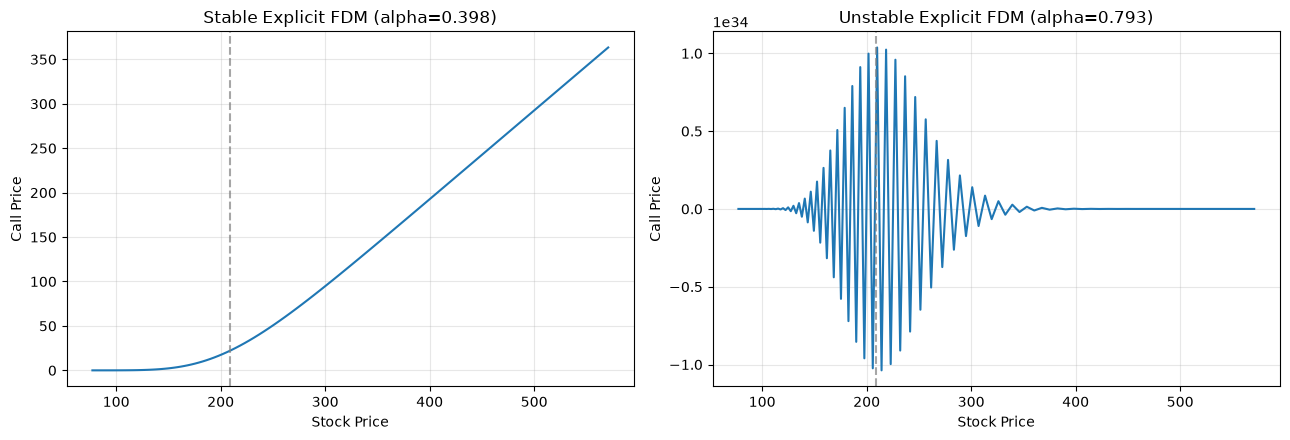

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(stable["S_grid"], stable["C_grid"])
axes[0].axvline(s0, linestyle="--", color="gray", alpha=0.7)
axes[0].set_title(f"Stable Explicit FDM (alpha={stable['alpha']:.3f})")
axes[0].set_xlabel("Stock Price")
axes[0].set_ylabel("Call Price")
axes[0].grid(alpha=0.3)

axes[1].plot(unstable["S_grid"], unstable["C_grid"])
axes[1].axvline(s0, linestyle="--", color="gray", alpha=0.7)
axes[1].set_title(f"Unstable Explicit FDM (alpha={unstable['alpha']:.3f})")
axes[1].set_xlabel("Stock Price")
axes[1].set_ylabel("Call Price")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 16. Fully Implicit FDM: Tridiagonal Matrix Structure

The fully implicit discretization produces a tridiagonal linear system at each time step.

The main diagonal contains \(1+2\alpha\), while the lower and upper diagonals contain \(-\alpha\). Only the interior spatial nodes are included as unknowns; the boundary contributions are incorporated into the right-hand-side vector.

## 17. Tridiagonal LU Factorization

The tridiagonal coefficient matrix is factorized as \(A=LU\), where \(L\) is a unit lower-triangular matrix and \(U\) is an upper-triangular matrix.

The factorization is implemented directly using the three diagonals, avoiding the construction of a dense matrix. The resulting factors can be reused across time steps when the grid and time-step size remain fixed.

In [28]:
def tridiagonal_lu(lower, main, upper):

    m = len(main)

    l_factor = np.zeros(m - 1)
    u_diag = np.zeros(m)

    u_diag[0] = main[0]

    for i in range(1, m):
        l_factor[i - 1] = lower[i - 1] / u_diag[i - 1]

        u_diag[i] = (
            main[i]
            - l_factor[i - 1] * upper[i - 1]
        )

    return l_factor, u_diag

In [29]:
lower = np.array([-1.0, -1.0])
main = np.array([2.0, 2.0, 2.0])
upper = np.array([-1.0, -1.0])

l_factor, u_diag = tridiagonal_lu(lower, main, upper)

print("L lower diagonal:", l_factor)
print("U main diagonal:", u_diag)

L lower diagonal: [-0.5        -0.66666667]
U main diagonal: [2.         1.5        1.33333333]


## 18. Forward Substitution

After the tridiagonal LU factorization, the intermediate system \(Ly=d\) is solved using forward substitution.

Since \(L\) is a unit lower-triangular matrix, the first element of \(y\) equals the first element of the right-hand-side vector. Subsequent elements are calculated sequentially using the previously computed values.

In [30]:
def forward_substitution(l_factor, rhs):

    m = len(rhs)
    y = np.zeros(m)

    y[0] = rhs[0]

    for i in range(1, m):
        y[i] = rhs[i] - l_factor[i - 1] * y[i - 1]

    return y

## 19. Backward Substitution

The upper-triangular system \(Ux=y\) is solved using backward substitution.

The final unknown is calculated first, and the remaining unknowns are obtained sequentially in reverse order.

In [31]:
def backward_substitution(u_diag, upper, y):

    m = len(y)
    solution = np.zeros(m)

    solution[-1] = y[-1] / u_diag[-1]

    for i in range(m - 2, -1, -1):
        solution[i] = (
            y[i] - upper[i] * solution[i + 1]
        ) / u_diag[i]

    return solution

## 20. Testing the Tridiagonal LU Solver

The LU factorization, forward substitution, and backward substitution functions are combined to solve a tridiagonal linear system.

The numerical solution is checked by multiplying the original coefficient matrix by the computed solution and comparing the result with the right-hand-side vector.

In [32]:
lower = np.array([-1.0, -1.0])
main = np.array([2.0, 2.0, 2.0])
upper = np.array([-1.0, -1.0])

rhs = np.array([1.0, 0.0, 1.0])

l_factor, u_diag = tridiagonal_lu(lower, main, upper)

y = forward_substitution(l_factor, rhs)

solution = backward_substitution(u_diag, upper, y)

print("Solution:", solution)



A = np.array([
    [2.0, -1.0, 0.0],
    [-1.0, 2.0, -1.0],
    [0.0, -1.0, 2.0]
])

print("A @ solution:", A @ solution)
print("Original rhs:", rhs)

print("Correct:", np.allclose(A @ solution, rhs))

Solution: [1. 1. 1.]
A @ solution: [1.00000000e+00 1.11022302e-16 1.00000000e+00]
Original rhs: [1. 0. 1.]
Correct: True


## 21. Fully Implicit Finite Difference Method

The fully implicit method discretizes the heat equation using a backward difference in time and a central difference in space.

At each time step, the unknown interior grid values are obtained by solving a tridiagonal linear system. The coefficient matrix is factorized once using tridiagonal LU decomposition and reused for subsequent time steps.

The method is unconditionally stable, although sufficiently fine spatial and temporal grids are still needed for numerical accuracy.

In [33]:
def implicit_fdm(M, N, x_min=-1.0, x_max=1.0):

    # Black-Scholes to heat equation transformation
    k = 2 * r / sigma**2
    a = (1 - k) / 2
    b = -(k + 1)**2 / 4

    # Spatial and time grids
    x = np.linspace(x_min, x_max, M + 1)
    tau_max = 0.5 * sigma**2 * T

    dx = (x_max - x_min) / M
    dtau = tau_max / N
    alpha = dtau / dx**2

    tau = np.linspace(0, tau_max, N + 1)

    # Initialize solution grid
    u = np.zeros((N + 1, M + 1))

    # Initial condition
    u[0, :] = np.exp(-a * x) * np.maximum(np.exp(x) - 1, 0)

    # Boundary conditions
    u[:, 0] = 0.0

    u[:, -1] = (
        np.exp(-a * x_max - b * tau)
        * (np.exp(x_max) - np.exp(-k * tau))
    )

    # Tridiagonal coefficient matrix
    m = M - 1

    lower = np.full(m - 1, -alpha)
    main = np.full(m, 1 + 2 * alpha)
    upper = np.full(m - 1, -alpha)

    # LU factorization
    l_factor, u_diag = tridiagonal_lu(lower, main, upper)

    for n in range(N):

        # Interior values from previous time step
        rhs = u[n, 1:-1].copy()

        # Boundary contributions at the new time step
        rhs[0] += alpha * u[n + 1, 0]
        rhs[-1] += alpha * u[n + 1, -1]

        # Solve using LU
        y = forward_substitution(l_factor, rhs)

        u[n + 1, 1:-1] = backward_substitution(
            u_diag, upper, y
        )

    # Transform back to stock prices and option values
    S_grid = K * np.exp(x)

    C_grid = (
        K * np.exp(a * x + b * tau_max) * u[-1, :]
    )

    # Numerical Greeks
    delta_grid = np.gradient(
        C_grid, S_grid, edge_order=2
    )

    gamma_grid = np.gradient(
        delta_grid, S_grid, edge_order=2
    )

    # Interpolate at the current stock price
    call_price = np.interp(s0, S_grid, C_grid)
    delta = np.interp(s0, S_grid, delta_grid)
    gamma = np.interp(s0, S_grid, gamma_grid)

    return {
        "M": M,
        "N": N,
        "alpha": alpha,
        "Price": call_price,
        "Delta": delta,
        "Gamma": gamma
    }

## 22. Fully Implicit FDM: Initial Numerical Test

The fully implicit solver is tested using a spatial grid with 100 intervals and 200 time steps.

The computed call price, Delta, and Gamma are compared with the Black–Scholes analytical benchmarks to assess the numerical solution.

In [34]:
implicit_result = implicit_fdm(M=100, N=200)

for key, value in implicit_result.items():
    print(f"{key}: {value}")

M: 100
N: 200
alpha: 0.4161510396936986
Price: 22.15752492307938
Delta: 0.5625340211501013
Gamma: 0.007311442318715911


## 23. Fully Implicit FDM: Grid Convergence Analysis

The spatial and temporal grids are progressively refined to evaluate the convergence of the fully implicit finite difference method.

The numerical option price, Delta, and Gamma are compared with the Black–Scholes analytical benchmarks. The absolute errors are expected to decrease as the discretization becomes finer, although convergence may not be strictly monotonic due to interpolation and spatial approximation effects.

In [35]:
grid_settings = [
    (100, 200),
    (200, 800),
    (400, 3200)
]

implicit_results = []

for M, N in grid_settings:
    result = implicit_fdm(M=M, N=N)
    implicit_results.append(result)

implicit_df = pd.DataFrame(implicit_results)

implicit_df["Price Error"] = abs(
    implicit_df["Price"] - 22.175020
)

implicit_df["Delta Error"] = abs(
    implicit_df["Delta"] - 0.562879
)

implicit_df["Gamma Error"] = abs(
    implicit_df["Gamma"] - 0.007304
)

display(implicit_df)

,M,N,alpha,Price,Delta,Gamma,Price Error,Delta Error,Gamma Error
0,100,200,0.416151,22.157525,0.562534,0.007311,0.017495,0.000345,7.442319e-06
1,200,800,0.416151,22.171805,0.562783,0.007305,0.003215,0.000096,1.277551e-06
2,400,3200,0.416151,22.173564,0.562860,0.007304,0.001456,0.000019,1.569636e-07


## 24. Crank–Nicolson Finite Difference Method

The Crank–Nicolson method averages the spatial second derivatives at the current and next time levels.

The resulting scheme is second-order accurate in time and space for sufficiently smooth solutions. It requires solving a tridiagonal linear system at each time step.

The previously implemented tridiagonal LU solver is reused, with the coefficient matrix factorized only once.

In [36]:
def crank_nicolson_fdm(M, N, x_min=-1.0, x_max=1.0):

    # Black-Scholes to heat equation transformation
    k = 2 * r / sigma**2
    a = (1 - k) / 2
    b = -(k + 1)**2 / 4

    # Spatial and temporal grids
    x = np.linspace(x_min, x_max, M + 1)
    tau_max = 0.5 * sigma**2 * T

    dx = (x_max - x_min) / M
    dtau = tau_max / N
    alpha = dtau / dx**2

    tau = np.linspace(0, tau_max, N + 1)

    # Initialize the solution
    u = np.zeros((N + 1, M + 1))

    # Initial condition
    u[0, :] = (
        np.exp(-a * x)
        * np.maximum(np.exp(x) - 1, 0)
    )

    # Boundary conditions
    u[:, 0] = 0.0

    u[:, -1] = (
        np.exp(-a * x_max - b * tau)
        * (np.exp(x_max) - np.exp(-k * tau))
    )

    # Crank-Nicolson coefficient matrix
    m = M - 1

    lower = np.full(m - 1, -alpha / 2)
    main = np.full(m, 1 + alpha)
    upper = np.full(m - 1, -alpha / 2)

    # Factorize once and reuse
    l_factor, u_diag = tridiagonal_lu(
        lower, main, upper
    )

    for n in range(N):

        # RHS from the previous time level
        rhs = (
            (alpha / 2) * u[n, :-2]
            + (1 - alpha) * u[n, 1:-1]
            + (alpha / 2) * u[n, 2:]
        )

        # Boundary contributions at the new time level
        rhs[0] += (alpha / 2) * u[n + 1, 0]
        rhs[-1] += (alpha / 2) * u[n + 1, -1]

        # Solve the tridiagonal system
        y = forward_substitution(l_factor, rhs)

        u[n + 1, 1:-1] = backward_substitution(
            u_diag, upper, y
        )

    # Transform back to option prices
    S_grid = K * np.exp(x)

    C_grid = (
        K * np.exp(a * x + b * tau_max) * u[-1, :]
    )

    # Numerical Greeks
    delta_grid = np.gradient(
        C_grid, S_grid, edge_order=2
    )

    gamma_grid = np.gradient(
        delta_grid, S_grid, edge_order=2
    )

    # Interpolate at the current stock price
    call_price = np.interp(s0, S_grid, C_grid)
    delta = np.interp(s0, S_grid, delta_grid)
    gamma = np.interp(s0, S_grid, gamma_grid)

    return {
        "M": M,
        "N": N,
        "alpha": alpha,
        "Price": call_price,
        "Delta": delta,
        "Gamma": gamma
    }

## 25. Crank–Nicolson: Initial Numerical Test

The Crank–Nicolson solver is tested using 100 spatial intervals and 200 time steps.

Its numerical call price, Delta, and Gamma are compared with the fully implicit finite difference method and the Black–Scholes analytical solution.

In [37]:
cn_result = crank_nicolson_fdm(M=100, N=200)

comparison_df = pd.DataFrame([
    {"Method": "Fully Implicit", **implicit_fdm(100, 200)},
    {"Method": "Crank-Nicolson", **cn_result}
])

comparison_df["Price Error"] = abs(
    comparison_df["Price"] - 22.175020
)

comparison_df["Delta Error"] = abs(
    comparison_df["Delta"] - 0.562879
)

comparison_df["Gamma Error"] = abs(
    comparison_df["Gamma"] - 0.007304
)

display(comparison_df)

,Method,M,N,alpha,Price,Delta,Gamma,Price Error,Delta Error,Gamma Error
0,Fully Implicit,100,200,0.416151,22.157525,0.562534,0.007311,0.017495,0.000345,0.000007
1,Crank-Nicolson,100,200,0.416151,22.170427,0.562589,0.007298,0.004593,0.000290,0.000006


## 26. Crank–Nicolson Grid Convergence Analysis

The Crank–Nicolson method is evaluated using progressively refined spatial and temporal grids.

Numerical call prices and Greeks are compared against the Black–Scholes analytical benchmarks to examine convergence behavior.

In [38]:
cn_results = []

for M, N in grid_settings:
    result = crank_nicolson_fdm(M=M, N=N)
    cn_results.append(result)

cn_df = pd.DataFrame(cn_results)

cn_df["Price Error"] = abs(cn_df["Price"] - 22.175020)
cn_df["Delta Error"] = abs(cn_df["Delta"] - 0.562879)
cn_df["Gamma Error"] = abs(cn_df["Gamma"] - 0.007304)

display(cn_df)

,M,N,alpha,Price,Delta,Gamma,Price Error,Delta Error,Gamma Error
0,100,200,0.416151,22.170427,0.562589,0.007298,0.004593,0.000290,6.222893e-06
1,200,800,0.416151,22.175026,0.562797,0.007302,0.000006,0.000082,2.141792e-06
2,400,3200,0.416151,22.174369,0.562863,0.007303,0.000651,0.000016,6.983908e-07


## 27. Runtime Comparison Across FDM Methods

The computational runtime of the explicit, fully implicit, and Crank–Nicolson methods is compared using identical spatial and temporal grids.

Each solver is timed externally to include grid initialization, boundary conditions, matrix factorization where applicable, time stepping, and computation of option prices and Greeks.

Multiple repetitions are used to reduce timing noise.

In [39]:
def measure_runtime(func, repeats=5, **kwargs):
    runtimes = []

    for _ in range(repeats):
        start = perf_counter()
        result = func(**kwargs)
        runtimes.append(perf_counter() - start)

    return result, np.median(runtimes)


runtime_results = []

methods = [
    ("Explicit", explicit_fdm, {"M": 100, "alpha_target": 0.4}),
    ("Fully Implicit", implicit_fdm, {"M": 100, "N": 200}),
    ("Crank-Nicolson", crank_nicolson_fdm, {"M": 100, "N": 200})
]

for name, func, kwargs in methods:
    result, runtime = measure_runtime(func, **kwargs)

    runtime_results.append({
        "Method": name,
        "M": result["M"],
        "N": result["N"],
        "Alpha": result["alpha"],
        "Runtime (ms)": runtime * 1000,
        "Price Error": abs(result["Price"] - 22.175020)
    })

runtime_df = pd.DataFrame(runtime_results)

display(runtime_df)

,Method,M,N,Alpha,Runtime (ms),Price Error
0,Explicit,100,209,0.398231,0.9897,0.007729
1,Fully Implicit,100,200,0.416151,11.9135,0.017495
2,Crank-Nicolson,100,200,0.416151,12.7857,0.004593


## 28. Stability Test: Fully Implicit vs. Crank–Nicolson

The fully implicit and Crank–Nicolson methods are tested using a relatively large time-step ratio, with alpha greater than 0.5.

Both methods are unconditionally stable for the heat equation under the standard discretization. However, unconditional stability does not guarantee high numerical accuracy or the absence of oscillatory behavior in all cases.

In [40]:
stability_results = []

for name, func in [
    ("Fully Implicit", implicit_fdm),
    ("Crank-Nicolson", crank_nicolson_fdm)
]:
    result = func(M=100, N=50)

    stability_results.append({
        "Method": name,
        "M": result["M"],
        "N": result["N"],
        "Alpha": result["alpha"],
        "Price": result["Price"],
        "Price Error": abs(result["Price"] - 22.175020),
        "Delta": result["Delta"],
        "Gamma": result["Gamma"]
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df)

,Method,M,N,Alpha,Price,Price Error,Delta,Gamma
0,Fully Implicit,100,50,1.664604,22.118915,0.056105,0.562369,0.007353
1,Crank-Nicolson,100,50,1.664604,22.170674,0.004346,0.562590,0.007297


## 29. Truncation Range Sensitivity Analysis

The infinite spatial domain of the transformed Black–Scholes PDE must be truncated to a finite interval for numerical computation.

Three spatial domains are examined to assess how boundary placement and spatial resolution affect numerical pricing accuracy.

The number of spatial intervals and time steps is held fixed to isolate the effect of changing the truncation range.

In [41]:
truncation_ranges = [
    (-0.5, 0.5),
    (-1.0, 1.0),
    (-1.5, 1.5)
]

truncation_results = []

for x_min, x_max in truncation_ranges:

    for name, func in [
        ("Fully Implicit", implicit_fdm),
        ("Crank-Nicolson", crank_nicolson_fdm)
    ]:

        result = func(
            M=200,
            N=800,
            x_min=x_min,
            x_max=x_max
        )

        truncation_results.append({
            "Method": name,
            "x_min": x_min,
            "x_max": x_max,
            "dx": (x_max - x_min) / 200,
            "Price": result["Price"],
            "Price Error": abs(result["Price"] - 22.175020),
            "Delta Error": abs(result["Delta"] - 0.562879),
            "Gamma Error": abs(result["Gamma"] - 0.007304)
        })

truncation_df = pd.DataFrame(truncation_results)

display(truncation_df)

,Method,x_min,x_max,dx,Price,Price Error,Delta Error,Gamma Error
0,Fully Implicit,-0.5,0.5,0.005,22.169771,0.005249,0.000022,5.539228e-06
1,Crank-Nicolson,-0.5,0.5,0.005,22.173045,0.001975,0.000008,8.787960e-06
2,Fully Implicit,-1.0,1.0,0.010,22.171805,0.003215,0.000096,1.277551e-06
3,Crank-Nicolson,-1.0,1.0,0.010,22.175026,0.000006,0.000082,2.141792e-06
4,Fully Implicit,-1.5,1.5,0.015,22.170486,0.004534,0.000187,5.600792e-07
5,Crank-Nicolson,-1.5,1.5,0.015,22.173708,0.001312,0.000174,3.972771e-06


## 30. Truncation Sensitivity with Fixed Spatial Resolution

To isolate the impact of domain truncation, the spatial step size is held constant across different truncation ranges.

The number of spatial intervals is adjusted according to the domain width, while the number of time steps remains fixed.

This experiment separates boundary placement effects from changes in spatial discretization.

In [42]:
fixed_dx = 0.01
N = 800

fixed_dx_results = []

for x_min, x_max in truncation_ranges:

    M = int(round((x_max - x_min) / fixed_dx))

    for name, func in [
        ("Fully Implicit", implicit_fdm),
        ("Crank-Nicolson", crank_nicolson_fdm)
    ]:

        result = func(
            M=M,
            N=N,
            x_min=x_min,
            x_max=x_max
        )

        fixed_dx_results.append({
            "Method": name,
            "x_min": x_min,
            "x_max": x_max,
            "M": M,
            "N": N,
            "dx": (x_max - x_min) / M,
            "Price Error": abs(result["Price"] - 22.175020),
            "Delta Error": abs(result["Delta"] - 0.562879),
            "Gamma Error": abs(result["Gamma"] - 0.007304)
        })

fixed_dx_df = pd.DataFrame(fixed_dx_results)

display(fixed_dx_df)


,Method,x_min,x_max,M,N,dx,Price Error,Delta Error,Gamma Error
0,Fully Implicit,-0.5,0.5,100,800,0.01,0.004610,0.000088,0.000007
1,Crank-Nicolson,-0.5,0.5,100,800,0.01,0.001337,0.000074,0.000010
2,Fully Implicit,-1.0,1.0,200,800,0.01,0.003215,0.000096,0.000001
3,Crank-Nicolson,-1.0,1.0,200,800,0.01,0.000006,0.000082,0.000002
4,Fully Implicit,-1.5,1.5,300,800,0.01,0.003215,0.000096,0.000001
5,Crank-Nicolson,-1.5,1.5,300,800,0.01,0.000006,0.000082,0.000002


## 31. Fair Runtime Comparison Using Identical Grids

All three finite difference methods are benchmarked using identical spatial and temporal discretizations.

The explicit solver is extended to accept a fixed number of time steps, enabling direct comparisons of runtime, pricing accuracy, and computational efficiency.

In [43]:
fair_runtime_results = []

methods = [
    ("Explicit", explicit_fdm),
    ("Fully Implicit", implicit_fdm),
    ("Crank-Nicolson", crank_nicolson_fdm)
]

for name, func in methods:

    result, runtime = measure_runtime(
        func,
        repeats=10,
        M=100,
        N=200
    )

    fair_runtime_results.append({
        "Method": name,
        "M": result["M"],
        "N": result["N"],
        "Alpha": result["alpha"],
        "Price": result["Price"],
        "Delta": result["Delta"],
        "Gamma": result["Gamma"],
        "Runtime (ms)": runtime * 1000,
        "Price Error": abs(result["Price"] - 22.175020),
        "Delta Error": abs(result["Delta"] - 0.562879),
        "Gamma Error": abs(result["Gamma"] - 0.007304)
    })

fair_runtime_df = pd.DataFrame(fair_runtime_results)

display(fair_runtime_df)

,Method,M,N,Alpha,Price,Delta,Gamma,Runtime (ms),Price Error,Delta Error,Gamma Error
0,Explicit,100,200,0.416151,22.183304,0.562644,0.007284,1.63900,0.008284,0.000235,0.000020
1,Fully Implicit,100,200,0.416151,22.157525,0.562534,0.007311,12.66735,0.017495,0.000345,0.000007
2,Crank-Nicolson,100,200,0.416151,22.170427,0.562589,0.007298,12.43685,0.004593,0.000290,0.000006


## 34. Black–Scholes Analytical Benchmarks

The analytical European call price, Delta, and Gamma are calculated using the Black–Scholes formula.

Full numerical precision is retained when computing absolute errors for the finite difference methods.

In [44]:
d1 = (
    np.log(s0 / K)
    + (r + 0.5 * sigma**2) * T
) / (sigma * np.sqrt(T))

d2 = d1 - sigma * np.sqrt(T)

bs_price = (
    s0 * norm.cdf(d1)
    - K * np.exp(-r * T) * norm.cdf(d2)
)

bs_delta = norm.cdf(d1)

bs_gamma = norm.pdf(d1) / (s0 * sigma * np.sqrt(T))

print(f"BS Price: {bs_price:.10f}")
print(f"BS Delta: {bs_delta:.10f}")
print(f"BS Gamma: {bs_gamma:.10f}")

BS Price: 22.1750196599
BS Delta: 0.5628785217
BS Gamma: 0.0073035652


In [45]:
fair_runtime_df["Price Error"] = abs(
    fair_runtime_df["Price"] - bs_price
)

fair_runtime_df["Delta Error"] = abs(
    fair_runtime_df["Delta"] - bs_delta
)

fair_runtime_df["Gamma Error"] = abs(
    fair_runtime_df["Gamma"] - bs_gamma
)

display(fair_runtime_df)

,Method,M,N,Alpha,Price,Delta,Gamma,Runtime (ms),Price Error,Delta Error,Gamma Error
0,Explicit,100,200,0.416151,22.183304,0.562644,0.007284,1.63900,0.008285,0.000235,0.000019
1,Fully Implicit,100,200,0.416151,22.157525,0.562534,0.007311,12.66735,0.017495,0.000345,0.000008
2,Crank-Nicolson,100,200,0.416151,22.170427,0.562589,0.007298,12.43685,0.004592,0.000289,0.000006


## 35. Price Convergence Comparison Across FDM Methods

The absolute pricing errors of the explicit, fully implicit, and Crank–Nicolson methods are compared across three spatial grid resolutions.

The Black–Scholes analytical call price is used as the benchmark. A logarithmic vertical axis is used to make differences in numerical errors easier to observe.

In [46]:
## 35.1 Explicit FDM Convergence Data Preparation
##The explicit finite difference solver is evaluated at three spatial resolutions. The resulting numerical prices and their absolute errors are stored in a DataFrame for comparison with the implicit and Crank–Nicolson methods.
explicit_results = []

for M in [100, 200, 400]:
    result = explicit_fdm(M=M, alpha_target=0.4)
    explicit_results.append(result)

explicit_df = pd.DataFrame(explicit_results)

explicit_df["Price Error"] = abs(
    explicit_df["Price"] - bs_price
)

display(explicit_df)

,M,N,alpha,Price,Delta,Gamma,Runtime,Price Error
0,100,209,0.398231,22.182749,0.562642,0.007285,0.001574,0.007729
1,200,833,0.399665,22.178118,0.562810,0.007299,0.005509,0.003099
2,400,3330,0.399905,22.175143,0.562866,0.007302,0.025223,0.000123


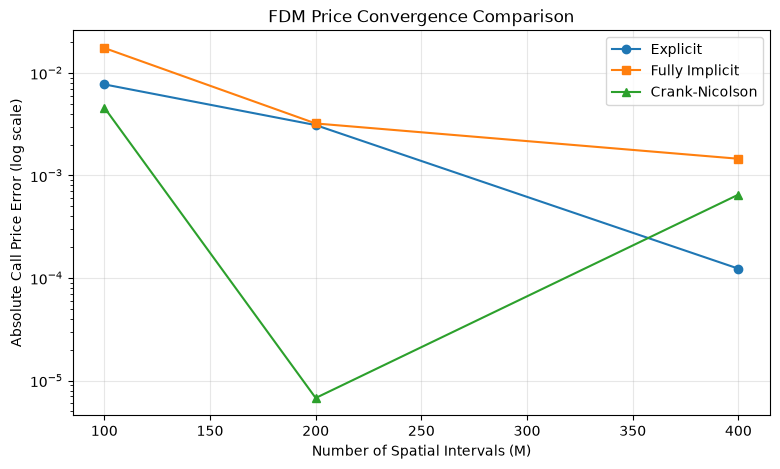

In [47]:
# Recalculate errors using the full-precision benchmark
explicit_df["Price Error"] = abs(explicit_df["Price"] - bs_price)
implicit_df["Price Error"] = abs(implicit_df["Price"] - bs_price)
cn_df["Price Error"] = abs(cn_df["Price"] - bs_price)

plt.figure(figsize=(9, 5))

plt.plot(
    explicit_df["M"],
    explicit_df["Price Error"],
    marker="o",
    label="Explicit"
)

plt.plot(
    implicit_df["M"],
    implicit_df["Price Error"],
    marker="s",
    label="Fully Implicit"
)

plt.plot(
    cn_df["M"],
    cn_df["Price Error"],
    marker="^",
    label="Crank-Nicolson"
)

plt.yscale("log")
plt.xlabel("Number of Spatial Intervals (M)")
plt.ylabel("Absolute Call Price Error (log scale)")
plt.title("FDM Price Convergence Comparison")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 36. Runtime–Accuracy Trade-off

The computational efficiency of the three finite difference methods is evaluated by comparing execution time against absolute call pricing error.

All methods use the same spatial and temporal grid. Lower runtime and lower pricing error are preferred.

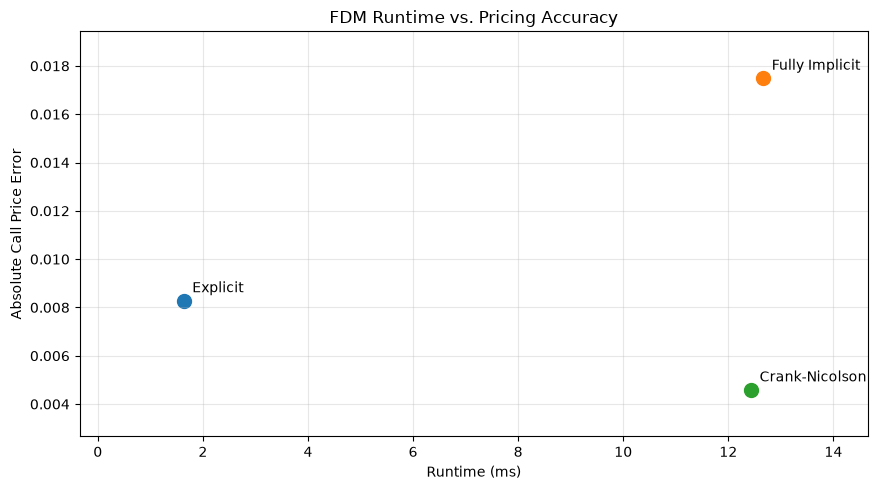

In [48]:
plt.figure(figsize=(9, 5))

for _, row in fair_runtime_df.iterrows():
    plt.scatter(
        row["Runtime (ms)"],
        row["Price Error"],
        s=100
    )

    plt.annotate(
        row["Method"],
        (row["Runtime (ms)"], row["Price Error"]),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.xlabel("Runtime (ms)")
plt.ylabel("Absolute Call Price Error")
plt.title("FDM Runtime vs. Pricing Accuracy")
plt.grid(True, alpha=0.3)
plt.margins(x=0.18, y=0.15)
plt.tight_layout()
plt.show()

## 37. Domain Truncation Error Estimation

Domain truncation sensitivity is estimated by comparing finite difference prices across three spatial domains while holding the spatial and temporal step sizes constant.

The widest domain, [-1.5, 1.5], is used as the numerical reference. Differences from this reference measure sensitivity to boundary placement rather than total error against the Black–Scholes analytical price.

These differences are estimates of domain truncation effects, not exact truncation errors.

In [49]:
domain_results = []

fixed_dx = 0.01
fixed_N = 800

for x_min, x_max in truncation_ranges:

    M = int(round((x_max - x_min) / fixed_dx))

    for name, func in [
        ("Fully Implicit", implicit_fdm),
        ("Crank-Nicolson", crank_nicolson_fdm)
    ]:
        result = func(
            M=M,
            N=fixed_N,
            x_min=x_min,
            x_max=x_max
        )

        domain_results.append({
            "Method": name,
            "Domain": f"[{x_min}, {x_max}]",
            "M": M,
            "N": fixed_N,
            "dx": (x_max - x_min) / M,
            "Price": result["Price"]
        })

domain_df = pd.DataFrame(domain_results)

display(domain_df)

,Method,Domain,M,N,dx,Price
0,Fully Implicit,"[-0.5, 0.5]",100,800,0.01,22.170410
1,Crank-Nicolson,"[-0.5, 0.5]",100,800,0.01,22.173683
2,Fully Implicit,"[-1.0, 1.0]",200,800,0.01,22.171805
3,Crank-Nicolson,"[-1.0, 1.0]",200,800,0.01,22.175026
4,Fully Implicit,"[-1.5, 1.5]",300,800,0.01,22.171805
5,Crank-Nicolson,"[-1.5, 1.5]",300,800,0.01,22.175026


## 38. Domain Truncation Sensitivity Relative to a Wide Domain

For each numerical method, the widest spatial domain is used as the reference solution.

The absolute price difference between each truncated domain and the reference domain is reported as a domain sensitivity measure.

In [50]:
reference_prices = (
    domain_df[domain_df["Domain"] == "[-1.5, 1.5]"]
    .set_index("Method")["Price"]
)

domain_df["Reference Price"] = (
    domain_df["Method"].map(reference_prices)
)

domain_df["Domain Sensitivity"] = abs(
    domain_df["Price"] - domain_df["Reference Price"]
)

domain_df["Total BS Error"] = abs(
    domain_df["Price"] - bs_price
)

display(domain_df)

,Method,Domain,M,N,dx,Price,Reference Price,Domain Sensitivity,Total BS Error
0,Fully Implicit,"[-0.5, 0.5]",100,800,0.01,22.170410,22.171805,1.395456e-03,0.004610
1,Crank-Nicolson,"[-0.5, 0.5]",100,800,0.01,22.173683,22.175026,1.342963e-03,0.001336
2,Fully Implicit,"[-1.0, 1.0]",200,800,0.01,22.171805,22.171805,9.113954e-10,0.003214
3,Crank-Nicolson,"[-1.0, 1.0]",200,800,0.01,22.175026,22.175026,2.484484e-10,0.000007
4,Fully Implicit,"[-1.5, 1.5]",300,800,0.01,22.171805,22.171805,0.000000e+00,0.003214
5,Crank-Nicolson,"[-1.5, 1.5]",300,800,0.01,22.175026,22.175026,0.000000e+00,0.000007


## 39. Temporal Discretization Sensitivity

Temporal discretization sensitivity is evaluated by holding the spatial domain and spatial grid fixed while increasing the number of time steps.

The experiment uses a spatial domain of [-1, 1] with 200 spatial intervals. The number of time steps is increased from 200 to 1600.

Changes in numerical prices are used to assess the effect of temporal refinement. The Black–Scholes analytical price is retained as the benchmark for total pricing error.

In [51]:
temporal_results = []

for N in [200, 400, 800, 1600]:

    for name, func in [
        ("Fully Implicit", implicit_fdm),
        ("Crank-Nicolson", crank_nicolson_fdm)
    ]:

        result = func(
            M=200,
            N=N,
            x_min=-1.0,
            x_max=1.0
        )

        temporal_results.append({
            "Method": name,
            "M": 200,
            "N": N,
            "dx": 0.01,
            "dtau": 0.5 * sigma**2 * T / N,
            "Price": result["Price"],
            "Total BS Error": abs(result["Price"] - bs_price)
        })

temporal_df = pd.DataFrame(temporal_results)

display(temporal_df)

,Method,M,N,dx,dtau,Price,Total BS Error
0,Fully Implicit,200,200,0.01,0.000166,22.162149,0.012871
1,Crank-Nicolson,200,200,0.01,0.000166,22.175042,0.000022
2,Fully Implicit,200,400,0.01,0.000083,22.168586,0.006434
3,Crank-Nicolson,200,400,0.01,0.000083,22.175030,0.000010
4,Fully Implicit,200,800,0.01,0.000042,22.171805,0.003214
5,Crank-Nicolson,200,800,0.01,0.000042,22.175026,0.000007
6,Fully Implicit,200,1600,0.01,0.000021,22.173415,0.001604
7,Crank-Nicolson,200,1600,0.01,0.000021,22.175026,0.000006


## 40. Isolating Temporal Discretization Effects

A finely resolved temporal grid with 6400 time steps is used as a numerical reference for each finite difference method.

The spatial domain and spatial grid are held constant. Absolute price differences relative to the fine-time reference are used to estimate temporal discretization sensitivity.

The reference solution still contains spatial discretization and interpolation errors.

In [52]:
temporal_ref_prices = {}

for name, func in [
    ("Fully Implicit", implicit_fdm),
    ("Crank-Nicolson", crank_nicolson_fdm)
]:
    ref_result = func(
        M=200,
        N=6400,
        x_min=-1.0,
        x_max=1.0
    )

    temporal_ref_prices[name] = ref_result["Price"]

temporal_df["Temporal Reference"] = (
    temporal_df["Method"].map(temporal_ref_prices)
)

temporal_df["Temporal Sensitivity"] = abs(
    temporal_df["Price"] - temporal_df["Temporal Reference"]
)

display(
    temporal_df[
        [
            "Method",
            "N",
            "Price",
            "Temporal Sensitivity",
            "Total BS Error"
        ]
    ]
)

,Method,N,Price,Temporal Sensitivity,Total BS Error
0,Fully Implicit,200,22.162149,1.247427e-02,0.012871
1,Crank-Nicolson,200,22.175042,1.642618e-05,0.000022
2,Fully Implicit,400,22.168586,6.036870e-03,0.006434
3,Crank-Nicolson,400,22.175030,4.094525e-06,0.000010
4,Fully Implicit,800,22.171805,2.817423e-03,0.003214
5,Crank-Nicolson,800,22.175026,1.011583e-06,0.000007
6,Fully Implicit,1600,22.173415,1.207513e-03,0.001604
7,Crank-Nicolson,1600,22.175026,2.408449e-07,0.000006


### Temporal Convergence Findings

The fully implicit method exhibits approximately first-order temporal convergence, whereas the Crank–Nicolson method demonstrates approximately second-order temporal convergence.

When the number of time steps is doubled, the temporal sensitivity of Crank–Nicolson decreases by approximately a factor of four, consistent with its theoretical second-order temporal accuracy.

The comparison against a fine-time numerical reference helps distinguish temporal discretization effects from the total pricing error measured against the Black–Scholes analytical benchmark.

## 41. Spatial Discretization Sensitivity

Spatial discretization sensitivity is evaluated by holding the spatial domain and number of time steps fixed while refining the spatial grid.

The experiment uses the domain [-1, 1], with 6400 time steps and spatial intervals of 100, 200, and 400.

A fine temporal grid is selected to reduce the influence of temporal discretization error when examining spatial convergence.

In [53]:
spatial_results = []

for M in [100, 200, 400]:

    for name, func in [
        ("Fully Implicit", implicit_fdm),
        ("Crank-Nicolson", crank_nicolson_fdm)
    ]:

        result = func(
            M=M,
            N=6400,
            x_min=-1.0,
            x_max=1.0
        )

        spatial_results.append({
            "Method": name,
            "M": M,
            "N": 6400,
            "dx": 2.0 / M,
            "Price": result["Price"],
            "Total BS Error": abs(result["Price"] - bs_price)
        })

spatial_df = pd.DataFrame(spatial_results)

display(spatial_df)

,Method,M,N,dx,Price,Total BS Error
0,Fully Implicit,100,6400,0.020,22.170008,0.005012
1,Crank-Nicolson,100,6400,0.020,22.170411,0.004609
2,Fully Implicit,200,6400,0.010,22.174623,0.000397
3,Crank-Nicolson,200,6400,0.010,22.175025,0.000006
4,Fully Implicit,400,6400,0.005,22.173967,0.001053
5,Crank-Nicolson,400,6400,0.005,22.174369,0.000650


## 42. Isolating Spatial Discretization Effects

A finer spatial grid with 800 intervals is used as the numerical reference.

The spatial domain and number of time steps remain fixed. Differences from the fine-grid reference are used to estimate spatial discretization sensitivity.

These estimates also include changes in interpolation error and do not represent exact spatial truncation errors.

In [54]:
spatial_ref_prices = {}

for name, func in [
    ("Fully Implicit", implicit_fdm),
    ("Crank-Nicolson", crank_nicolson_fdm)
]:

    ref_result = func(
        M=800,
        N=6400,
        x_min=-1.0,
        x_max=1.0
    )

    spatial_ref_prices[name] = ref_result["Price"]

spatial_df["Spatial Reference"] = (
    spatial_df["Method"].map(spatial_ref_prices)
)

spatial_df["Spatial Sensitivity"] = abs(
    spatial_df["Price"] - spatial_df["Spatial Reference"]
)

display(
    spatial_df[
        [
            "Method",
            "M",
            "dx",
            "Price",
            "Spatial Sensitivity",
            "Total BS Error"
        ]
    ]
)

,Method,M,dx,Price,Spatial Sensitivity,Total BS Error
0,Fully Implicit,100,0.020,22.170008,0.004514,0.005012
1,Crank-Nicolson,100,0.020,22.170411,0.004513,0.004609
2,Fully Implicit,200,0.010,22.174623,0.000101,0.000397
3,Crank-Nicolson,200,0.010,22.175025,0.000101,0.000006
4,Fully Implicit,400,0.005,22.173967,0.000555,0.001053
5,Crank-Nicolson,400,0.005,22.174369,0.000555,0.000650


## 43. Error Decomposition and Recommended Grid

Three controlled numerical experiments were conducted to distinguish the effects of domain truncation, temporal discretization, and spatial discretization.

**Domain truncation:** With the spatial and temporal step sizes fixed, extending the computational domain from [-1, 1] to [-1.5, 1.5] produced negligible changes in the option price. This indicates that [-1, 1] is sufficiently wide for the selected option parameters.

**Temporal discretization:** Holding the spatial grid fixed and refining the time steps showed approximately first-order temporal convergence for the fully implicit method and second-order convergence for the Crank–Nicolson method.

**Spatial discretization:** With a fixed fine temporal grid, refining the spatial resolution produced non-monotonic price differences relative to a finer reference grid. This behavior may be influenced by the interaction between spatial discretization and interpolation errors.

The reported domain, temporal, and spatial sensitivity measures are numerical estimates rather than an exact additive decomposition of total pricing error.

**Recommended configuration:** The Crank–Nicolson method with spatial domain [-1, 1], 200 spatial intervals, and 800 time steps is selected as a practical benchmark configuration. It achieves a small absolute pricing error while avoiding the conditional stability restriction of the explicit method.

The unusually small pricing error at this grid resolution may partly reflect error cancellation; therefore, the recommendation should not be interpreted as proof that this is the globally optimal grid.

### Numerical Results and Discussion

**Convergence and Accuracy.** All three finite difference methods produced European call option prices close to the Black–Scholes analytical benchmark. Grid refinement generally improved numerical accuracy, although the Crank–Nicolson pricing error was not strictly monotonic. This behavior may reflect the interaction of spatial discretization, temporal discretization, and interpolation errors.

**Stability.** The explicit method exhibited severe numerical instability when the time-step ratio exceeded its stability threshold of 0.5. In contrast, the fully implicit and Crank–Nicolson methods remained numerically stable in the tested configurations with larger time steps. Stability, however, does not necessarily imply high accuracy.

**Computational Efficiency.** Under the common grid configuration of 100 spatial intervals and 200 time steps, the explicit method was the fastest in the current NumPy/Python implementation. Crank–Nicolson achieved the lowest absolute pricing error, while the fully implicit method exhibited a larger pricing error at a similar runtime. The observed performance differences depend partly on implementation details, particularly the use of vectorized operations versus Python-based triangular substitutions.

**Domain Truncation.** Holding the spatial resolution fixed showed that expanding the transformed spatial domain from [-0.5, 0.5] to [-1, 1] improved pricing accuracy. Further expansion to [-1.5, 1.5] produced negligible changes, suggesting that [-1, 1] provides an adequate computational domain for the selected option parameters.

**Conclusion.** Crank–Nicolson offered a favorable pricing accuracy–runtime trade-off among the three methods in the tested configuration. The explicit method was computationally efficient but required careful time-step selection, while the fully implicit method provided robust stability with lower temporal accuracy.

### Exporting Explicit Finite-Difference Results

The stable explicit finite-difference convergence results are exported for reconciliation. The finest tested stable grid is selected as the representative explicit estimate.

In [55]:
grid_df.to_csv("../Data/processed/explicit_fdm_results.csv", index=False)

### Runtime Measurement for Implicit Finite-Difference Schemes

The fully implicit and Crank–Nicolson schemes are timed on the selected spatial and temporal grid. Each method is executed repeatedly, and the median runtime is reported to reduce timing variability.

In [56]:
from time import perf_counter
import numpy as np

def median_runtime(func, repeats=5, **kwargs):
    times = []

    for _ in range(repeats):
        start = perf_counter()
        func(**kwargs)
        times.append(perf_counter() - start)

    return np.median(times)

implicit_runtime = median_runtime(
    implicit_fdm, M=200, N=6400
)

cn_runtime = median_runtime(
    crank_nicolson_fdm, M=200, N=6400
)

print("Fully Implicit Runtime:", implicit_runtime)
print("Crank-Nicolson Runtime:", cn_runtime)

Fully Implicit Runtime: 0.767151299995021
Crank-Nicolson Runtime: 0.8032648000080371


In [58]:
bs_call = 22.175019659856545 #from Q1
explicit_row = grid_df.loc[grid_df["M"] == 400].iloc[0]

fdm_results = pd.DataFrame([
    {
        "Method": "Explicit FDM",
        "M": 400,
        "N": int(explicit_row["N"]),
        "Price": explicit_row["Price"],
        "Runtime (s)": explicit_row["Runtime"],
        "Price Error": explicit_row["Price Error"]
    },
    {
        "Method": "Fully Implicit FDM",
        "M": 200,
        "N": 6400,
        "Price": 22.174623,
        "Runtime (s)": implicit_runtime,
        "Price Error": abs(22.174623 - bs_call)
    },
    {
        "Method": "Crank-Nicolson FDM",
        "M": 200,
        "N": 6400,
        "Price": 22.175025,
        "Runtime (s)": cn_runtime,
        "Price Error": abs(22.175025 - bs_call)
    }
])

display(fdm_results)

fdm_results.to_csv(
    "../Data/processed/fdm_reconciliation.csv",
    index=False
)

,Method,M,N,Price,Runtime (s),Price Error
0,Explicit FDM,400,3330,22.175143,0.024103,0.000123
1,Fully Implicit FDM,200,6400,22.174623,0.767151,0.000397
2,Crank-Nicolson FDM,200,6400,22.175025,0.803265,0.000005
